In [319]:
import re
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC


# 
import warnings
from sklearn.exceptions import UndefinedMetricWarning

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

In [272]:
FILE_PATH = "mail_data.csv"
TARGET_COL = "Category"
TEXT_COL = "Message"

In [273]:
df = pd.read_csv(FILE_PATH)
df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [274]:
print("Shape :\n", df.shape)
print('-'*100)
print("Types :\n", df.dtypes)
print('-'*100)
print("Null values :\n", df.isnull().sum())
print('-'*100)
print("duplicated :\n", df.duplicated().sum())
print('-'*100)
print(df[TARGET_COL].value_counts())
print('-'*100)
print(df[TARGET_COL].value_counts(normalize=True))
print('-'*100)
print(df.sample(5, random_state=42))

Shape :
 (5572, 2)
----------------------------------------------------------------------------------------------------
Types :
 Category    object
Message     object
dtype: object
----------------------------------------------------------------------------------------------------
Null values :
 Category    0
Message     0
dtype: int64
----------------------------------------------------------------------------------------------------
duplicated :
 415
----------------------------------------------------------------------------------------------------
Category
ham     4825
spam     747
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------
Category
ham     0.865937
spam    0.134063
Name: proportion, dtype: float64
----------------------------------------------------------------------------------------------------
     Category                                            Message
3245      ham  Squeeeeeze!! This is ch

## Clean - inspect suspicious rows

In [275]:
dup_by_class = df[df.duplicated()][TARGET_COL].value_counts()
print("Duplicates by class:")
dup_by_class

Duplicates by class:


Category
ham     309
spam    106
Name: count, dtype: int64

In [276]:
df['Message'].value_counts().to_frame().head(10)

,count
Message,
"Sorry, I'll call later",30
I cant pick the phone right now. Pls send a message,12
Ok...,10
Ok,4
Ok.,4
Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am-11pm as you have WON a guaranteed £1000 cash or £5000 prize!,4
"7 wonders in My WORLD 7th You 6th Ur style 5th Ur smile 4th Ur Personality 3rd Ur Nature 2nd Ur SMS and 1st ""Ur Lovely Friendship""... good morning dear",4
"Say this slowly.? GOD,I LOVE YOU &amp; I NEED YOU,CLEAN MY HEART WITH YOUR BLOOD.Send this to Ten special people &amp; u c miracle tomorrow, do it,pls,pls do it...",4
Your opinion about me? 1. Over 2. Jada 3. Kusruthi 4. Lovable 5. Silent 6. Spl character 7. Not matured 8. Stylish 9. Simple Pls reply..,4


In [277]:
label_counts = df.groupby("Message")[TARGET_COL].nunique()
label_counts.value_counts()

Category
1    5157
Name: count, dtype: int64

In [278]:
lenghts = df["Message"].str.strip().str.len()
lenghts.min()

2

In [279]:
(lenghts < 5).sum()

np.int64(18)

In [280]:
print("Rows now:", df.shape[0])
print('-'*100)
print("Rows after exact-duplicate removal would be:", len(df.drop_duplicates()))
print('-'*100)
print(df.drop_duplicates()["Category"].value_counts())

Rows now: 5572
----------------------------------------------------------------------------------------------------
Rows after exact-duplicate removal would be: 5157
----------------------------------------------------------------------------------------------------
Category
ham     4516
spam     641
Name: count, dtype: int64


## Remove duplicates BEFORE splitting

In [281]:
rows_before = len(df)
rows_before

5572

In [282]:
df = df.drop_duplicates(keep='first').reset_index(drop=True)

In [283]:
print("Rows before:", rows_before)
print("Rows after:", len(df))
print("Removed:", rows_before - len(df))

Rows before: 5572
Rows after: 5157
Removed: 415


In [284]:
dp_msg_left = df.duplicated(subset=['Message']).sum()
print("Duplicate messages left:", dp_msg_left)

Duplicate messages left: 0


In [285]:
df[TARGET_COL].value_counts()

Category
ham     4516
spam     641
Name: count, dtype: int64

## Split into train and test

In [286]:
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Shapes:")
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train:", y_train.shape, "y_test:", y_test.shape)
print('-'*140)
print("Test messages also found in train:", X_test.isin(X_train).sum())

Shapes:
X_train: (4125, 1) X_test: (1032, 1)
y_train: (4125,) y_test: (1032,)
--------------------------------------------------------------------------------------------------------------------------------------------
Test messages also found in train: Message    0
dtype: int64


In [287]:
print(y_train.value_counts())
print('-'*140)
print(y_train.value_counts(normalize=True))
print('-'*140)
print(y_test.value_counts())
print('-'*140)
print(y_test.value_counts(normalize=True))

Category
ham     3612
spam     513
Name: count, dtype: int64
--------------------------------------------------------------------------------------------------------------------------------------------
Category
ham     0.875636
spam    0.124364
Name: proportion, dtype: float64
--------------------------------------------------------------------------------------------------------------------------------------------
Category
ham     904
spam    128
Name: count, dtype: int64
--------------------------------------------------------------------------------------------------------------------------------------------
Category
ham     0.875969
spam    0.124031
Name: proportion, dtype: float64


## EDA - class balance bar chart

In [288]:
y_train_counts = y_train.value_counts()
print("index:", y_train_counts.index)
print("values:", y_train_counts.values)

index: Index(['ham', 'spam'], dtype='object', name='Category')
values: [3612  513]


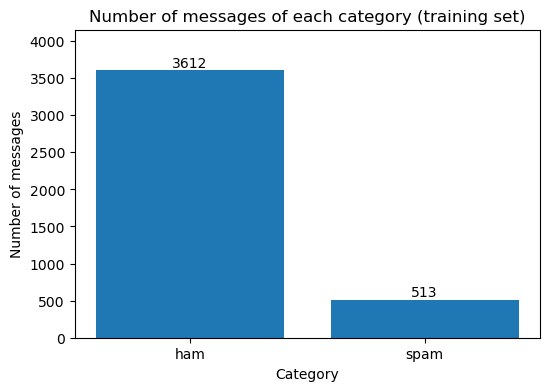

In [289]:
plt.figure(figsize=(6, 4))
plt.bar(y_train_counts.index, y_train_counts.values)
plt.xlabel(TARGET_COL)
plt.ylabel("Number of messages")
plt.title("Number of messages of each category (training set)")
for i, v in enumerate(y_train_counts.values): 
    plt.text(i, v, str(v), ha="center", va="bottom")
plt.ylim(0, y_train_counts.max() * 1.15)
plt.show()

## EDA - message length per class

In [290]:
X_train_lengths = X_train['Message'].str.len()
X_train_lengths

4469     62
749     151
3443     55
4743    149
4505    152
       ... 
2805    119
262      35
3859    154
2630    102
997      24
Name: Message, Length: 4125, dtype: int64

In [291]:
ham_len = X_train_lengths[y_train == 'ham']
spam_len = X_train_lengths[y_train == 'spam']

print("ham len:\n", ham_len)
print("-"*50)
print("spam len\n",spam_len)

ham len:
 4469     62
749     151
3443     55
215      41
4806     24
       ... 
4808     24
262      35
3859    154
2630    102
997      24
Name: Message, Length: 3612, dtype: int64
--------------------------------------------------
spam len
 4743    149
4505    152
1267    155
3046    157
266     133
       ... 
2584    160
1574    146
4099    156
3248    153
2805    119
Name: Message, Length: 513, dtype: int64


In [292]:
print("median ham len : ", ham_len.median())
print("max ham len : ", ham_len.max())
print('-'*75)
print("median spam len : ", spam_len.median())
print("max spam len : ", spam_len.max())

median ham len :  53.0
max ham len :  910
---------------------------------------------------------------------------
median spam len :  148.0
max spam len :  197


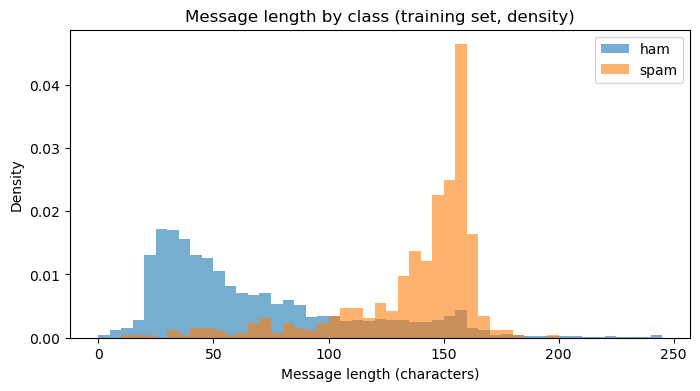

In [293]:
plt.figure(figsize=(8, 4))
plt.hist(ham_len, bins=range(0, 250, 5), alpha=0.6, density=True, label="ham")
plt.hist(spam_len, bins=range(0, 250, 5), alpha=0.6, density=True, label="spam")
plt.title("Message length by class (training set, density)")
plt.ylabel("Density")
plt.xlabel("Message length (characters)")
plt.legend()
plt.show()

## Most frequent words per class

In [294]:
def top_words(text, n=15):
    # count each word once per message, ignore English stop words
    counter_vector = CountVectorizer(stop_words="english", binary=True)
    matrix = counter_vector.fit_transform(text)

    # in how many messages does each word appear? (flat array)
    text_counts = matrix.sum(axis=0).A1

    # percentage of messages in this class that contain each word
    pct = (text_counts / matrix.shape[0]) * 100

    # positions of the n biggest percentages, largest first
    order = pct.argsort()[::-1][:n]

    # use the SAME positions on both arrays so each word keeps its own number
    all_words = counter_vector.get_feature_names_out()
    top_w = all_words[order]
    top_p = pct[order]

    print(len(top_w), len(top_p))   # quick check: both should be 15
    return top_w, top_p 

In [295]:
ham_texts = X_train["Message"][y_train == 'ham']
spam_texts = X_train["Message"][y_train == 'spam']
ham_texts

4469    Saw Guys and Dolls last night with Patrick Swa...
749     Nothing but we jus tot u would ask cos u ba gu...
3443    Oh really?? Did you make it on air? What's you...
215             Easy ah?sen got selected means its good..
4806                             Oh did you charge camera
                              ...                        
4808                             Now i'm going for lunch.
262                   Same. Wana plan a trip sometme then
3859    Where are you ? What do you do ? How can you s...
2630    Can meh? Thgt some will clash... Really ah, i ...
997                              May i call You later Pls
Name: Message, Length: 3612, dtype: object

In [296]:
ham_words, ham_pct = top_words(ham_texts)
spam_words, spam_pct = top_words(spam_texts)

15 15
15 15


In [297]:
print("HAM  :", list(zip(ham_words, ham_pct.round(1))))
print()
print("SPAM :", list(zip(spam_words, spam_pct.round(1))))

HAM  : [('just', np.float64(6.2)), ('ok', np.float64(5.6)), ('gt', np.float64(5.0)), ('lt', np.float64(5.0)), ('know', np.float64(4.8)), ('ll', np.float64(4.8)), ('good', np.float64(4.6)), ('like', np.float64(4.5)), ('got', np.float64(4.4)), ('come', np.float64(4.3)), ('time', np.float64(3.8)), ('day', np.float64(3.8)), ('ur', np.float64(3.7)), ('going', np.float64(3.7)), ('want', np.float64(3.5))]

SPAM : [('free', np.float64(21.8)), ('txt', np.float64(20.3)), ('mobile', np.float64(15.6)), ('ur', np.float64(14.4)), ('text', np.float64(13.8)), ('claim', np.float64(13.8)), ('stop', np.float64(13.1)), ('reply', np.float64(13.1)), ('www', np.float64(12.7)), ('just', np.float64(10.9)), ('prize', np.float64(10.7)), ('new', np.float64(9.6)), ('won', np.float64(9.6)), ('150p', np.float64(9.6)), ('urgent', np.float64(9.2))]


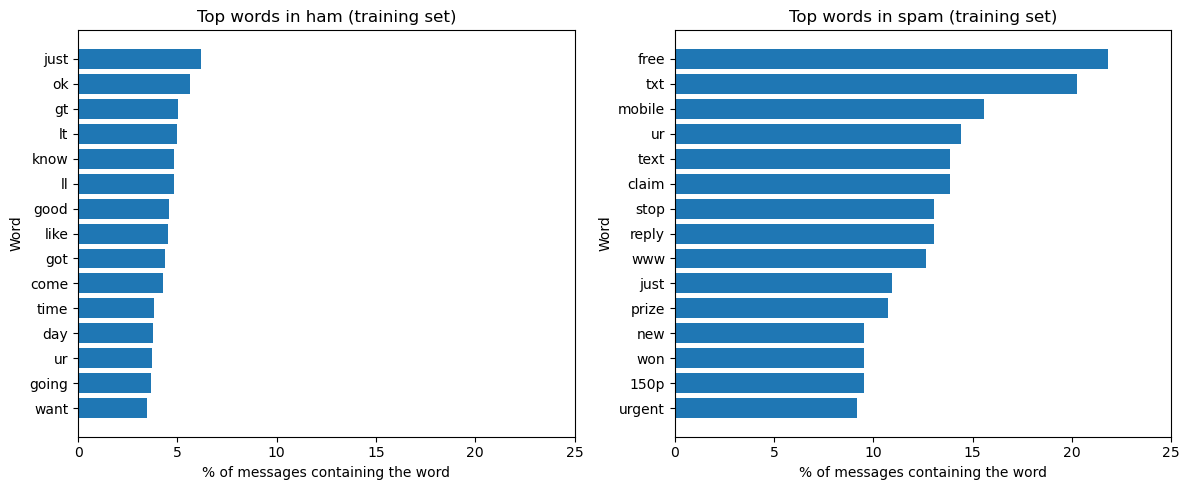

In [298]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(ham_words[::-1], ham_pct[::-1])
axes[1].barh(spam_words[::-1], spam_pct[::-1])
axes[0].set_title("Top words in ham (training set)")
axes[1].set_title("Top words in spam (training set)")
for ax in axes:
    ax.set_xlim(0, 25)
    ax.set_xlabel("% of messages containing the word")
    ax.set_ylabel("Word")
plt.tight_layout()
plt.show()

In [299]:
for w in ["free", "ur", "just"]:
    in_ham  = ham_texts.str.contains(rf"\b{w}\b", case=False, regex=True).mean() * 100
    in_spam = spam_texts.str.contains(rf"\b{w}\b", case=False, regex=True).mean() * 100
    print(w, round(in_ham, 1), round(in_spam, 1))

free 1.1 21.8
ur 3.7 14.4
just 6.2 10.9


In [300]:
X_train['Message'][X_train['Message'].str.contains("&lt;")].head()

2406        Ok ill send you with in  &lt;DECIMAL&gt;  ok.
2786    Yo do you know anyone  &lt;#&gt;  or otherwise...
3879                               Just got to  &lt;#&gt;
782     Appt is at &lt;TIME&gt; am. Not my fault u don...
2149    Every day i use to sleep after  &lt;#&gt;  so ...
Name: Message, dtype: object

## EDA - check the placeholder tags

In [301]:
has_tags = X_train['Message'].str.contains("&lt;|&gt;", regex=True)

In [302]:
print(has_tags.groupby(y_train).mean()*100)

Category
ham     5.066445
spam    0.000000
Name: Message, dtype: float64


In [303]:
print(has_tags.groupby(y_train).sum())

Category
ham     183
spam      0
Name: Message, dtype: int64


## Preprocessing - fix the feature column and build the TF-IDF part

In [304]:
X_train_text = X_train[TEXT_COL]
X_test_text = X_test[TEXT_COL]
print(type(X_train_text), X_train_text.shape)

<class 'pandas.core.series.Series'> (4125,)


In [305]:
def clean(text):
    text = text.lower()
    text = re.sub(r"&lt;.*?&gt;", " ", text)
    text = re.sub(r"&(lt|gt);", " ", text)
    return text

In [306]:
tfidf = TfidfVectorizer(preprocessor=clean, stop_words='english')

In [307]:
tfidf

TfidfVectorizer(preprocessor=<function clean at 0x30d5f0ea0>,
                stop_words='english')

In [308]:
prep = Pipeline([
    ('tfidf', tfidf)
])
prep

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(preprocessor=<function clean at 0x30d5f0ea0>,
                                 stop_words='english'))])

In [309]:
X_train_vec = prep.fit_transform(X_train_text)
X_train_vec

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 31195 stored elements and shape (4125, 7407)>

In [310]:
vocab = prep.named_steps["tfidf"].vocabulary_

print("Train matrix shape:", X_train_vec.shape)
print("'lt' in vocabulary:", "lt" in vocab)
print("'gt' in vocabulary:", "gt" in vocab)

Train matrix shape: (4125, 7407)
'lt' in vocabulary: True
'gt' in vocabulary: True


In [311]:
cleaned = X_train_text.apply(clean)
print("Train matrix shape:", X_train_vec.shape)
print("Messages still containing '&lt;' or '&gt;':",
      cleaned.str.contains(r"&(?:lt|gt);", regex=True).sum())

Train matrix shape: (4125, 7407)
Messages still containing '&lt;' or '&gt;': 0


## Baseline - DummyClassifier

In [312]:
y_train_bin = (y_train == 'spam').astype(int)
print("Spam share in y_train_bin:", y_train_bin.mean())

Spam share in y_train_bin: 0.12436363636363636


In [313]:
dummy_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(preprocessor=clean ,stop_words='english')),
    ('model', DummyClassifier(strategy="most_frequent"))
])
dummy_pipe

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(preprocessor=<function clean at 0x30d5f0ea0>,
                                 stop_words='english')),
                ('model', DummyClassifier(strategy='most_frequent'))])

In [323]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

In [315]:
scoring = ["accuracy", "precision", "recall", "f1", "average_precision"]
results = cross_validate(dummy_pipe, X_train_text, y_train_bin, cv=cv, scoring=scoring)
results

{'fit_time': array([0.02789307, 0.01870394, 0.01853681, 0.01848888, 0.01892185]),
 'score_time': array([0.01099586, 0.00984311, 0.00989819, 0.01017594, 0.00977802]),
 'test_accuracy': array([0.87636364, 0.87636364, 0.87515152, 0.87515152, 0.87515152]),
 'test_precision': array([0., 0., 0., 0., 0.]),
 'test_recall': array([0., 0., 0., 0., 0.]),
 'test_f1': array([0., 0., 0., 0., 0.]),
 'test_average_precision': array([0.12363636, 0.12363636, 0.12484848, 0.12484848, 0.12484848])}

In [316]:
for name in scoring:
    print(name, results["test_" + name].mean().round(3))

accuracy 0.876
precision 0.0
recall 0.0
f1 0.0
average_precision 0.124


In [317]:
y_train_bin.value_counts()

Category
0    3612
1     513
Name: count, dtype: int64

In [318]:
y_train_bin.value_counts(normalize=True).round(3)*100

Category
0    87.6
1    12.4
Name: proportion, dtype: float64

## Compare Logistic Regression, Naive Bayes and Linear SVM (cross-validation, training set only)

In [326]:
models = {
    "LogReg": LogisticRegression(max_iter=1000),
    "NaiveBayes": MultinomialNB(),
    "LinearSVM": LinearSVC()
}

In [333]:
all_results = {}
all_results["Dummy"] = {s: results["test_" + s].mean() for s in scoring}

for name, mdl in models.items():
    models_pipe = Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=clean, stop_words="english")),
        ("model", mdl)
    ])
    res = cross_validate(models_pipe, X_train_text, y_train_bin, cv=cv, scoring=scoring)
    all_results[name] = {s: res["test_" + s].mean() for s in scoring}

In [334]:
print(pd.DataFrame(all_results).T.round(3))

            accuracy  precision  recall     f1  average_precision
Dummy          0.876      0.000   0.000  0.000              0.124
LogReg         0.950      0.984   0.608  0.751              0.957
NaiveBayes     0.961      1.000   0.684  0.812              0.950
LinearSVM      0.982      0.983   0.869  0.922              0.972


In [335]:
print("Rows in table:", len(all_results))

Rows in table: 4
